Bizga kerakli kutubxonalarni chaqiramiz

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style as sty
import seaborn as sns

Datasetni yuklab olamiz

In [ ]:
df = pd.read_csv('USA_cars_datasets.csv',index_col=0)
df

,price,brand,model,year,title_status,mileage,color,vin,lot,state,country,condition
0,6300,toyota,cruiser,2008,clean vehicle,274117.0,black,jtezu11f88k007763,159348797,new jersey,usa,10 days left
1,2899,ford,se,2011,clean vehicle,190552.0,silver,2fmdk3gc4bbb02217,166951262,tennessee,usa,6 days left
2,5350,dodge,mpv,2018,clean vehicle,39590.0,silver,3c4pdcgg5jt346413,167655728,georgia,usa,2 days left
3,25000,ford,door,2014,clean vehicle,64146.0,blue,1ftfw1et4efc23745,167753855,virginia,usa,22 hours left
4,27700,chevrolet,1500,2018,clean vehicle,6654.0,red,3gcpcrec2jg473991,167763266,florida,usa,22 hours left
...,...,...,...,...,...,...,...,...,...,...,...,...
2494,7800,nissan,versa,2019,clean vehicle,23609.0,red,3n1cn7ap9kl880319,167722715,california,usa,1 days left
2495,9200,nissan,versa,2018,clean vehicle,34553.0,silver,3n1cn7ap5jl884088,167762225,florida,usa,21 hours left
2496,9200,nissan,versa,2018,clean vehicle,31594.0,silver,3n1cn7ap9jl884191,167762226,florida,usa,21 hours left
2497,9200,nissan,versa,2018,clean vehicle,32557.0,black,3n1cn7ap3jl883263,167762227,florida,usa,2 days left


Dataning hajmi

In [ ]:
df.shape

(2499, 12)

Dataning umumiy statistikasi

In [ ]:
df.describe()

,price,year,mileage,lot
count,2499.000000,2499.000000,2.499000e+03,2.499000e+03
mean,18767.671469,2016.714286,5.229869e+04,1.676914e+08
std,12116.094936,3.442656,5.970552e+04,2.038772e+05
min,0.000000,1973.000000,0.000000e+00,1.593488e+08
25%,10200.000000,2016.000000,2.146650e+04,1.676253e+08
50%,16900.000000,2018.000000,3.536500e+04,1.677451e+08
75%,25555.500000,2019.000000,6.347250e+04,1.677798e+08
max,84900.000000,2020.000000,1.017936e+06,1.678055e+08


Datadagi NaN qiymatlar soni

In [ ]:
df.isnull().sum()

price           0
brand           0
model           0
year            0
title_status    0
mileage         0
color           0
vin             0
lot             0
state           0
country         0
condition       0
dtype: int64

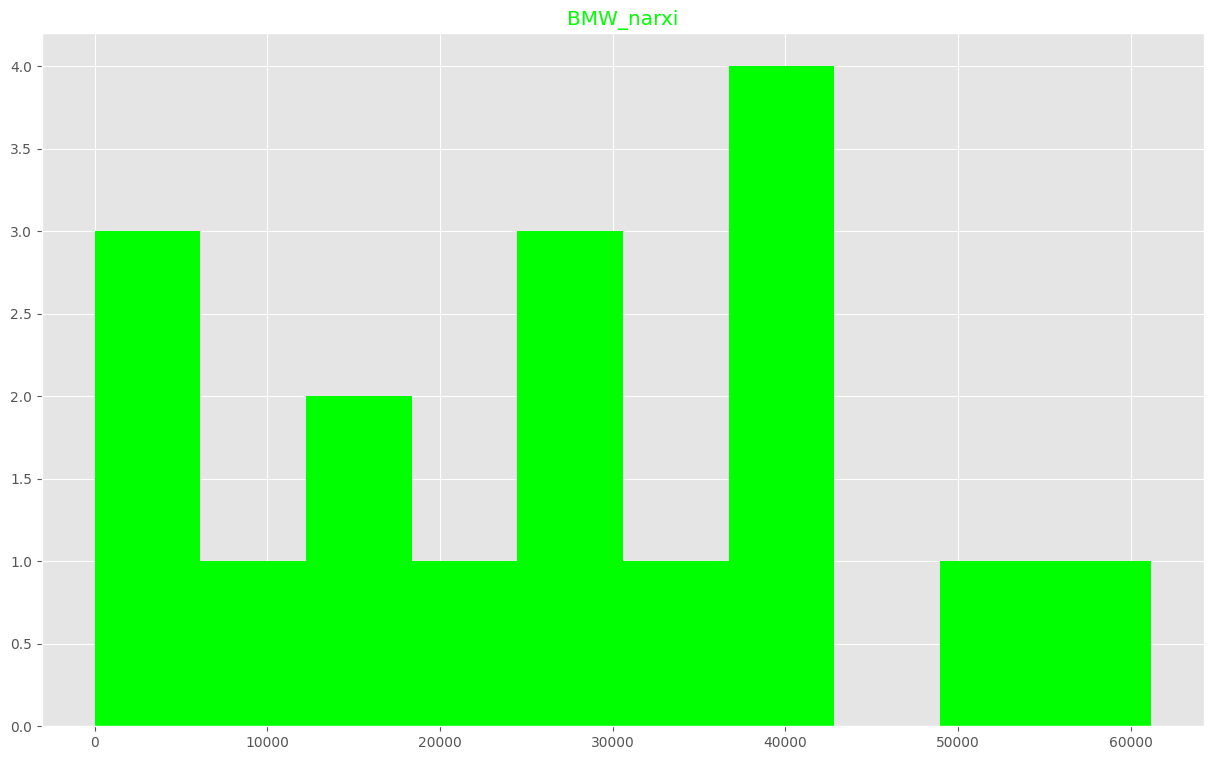

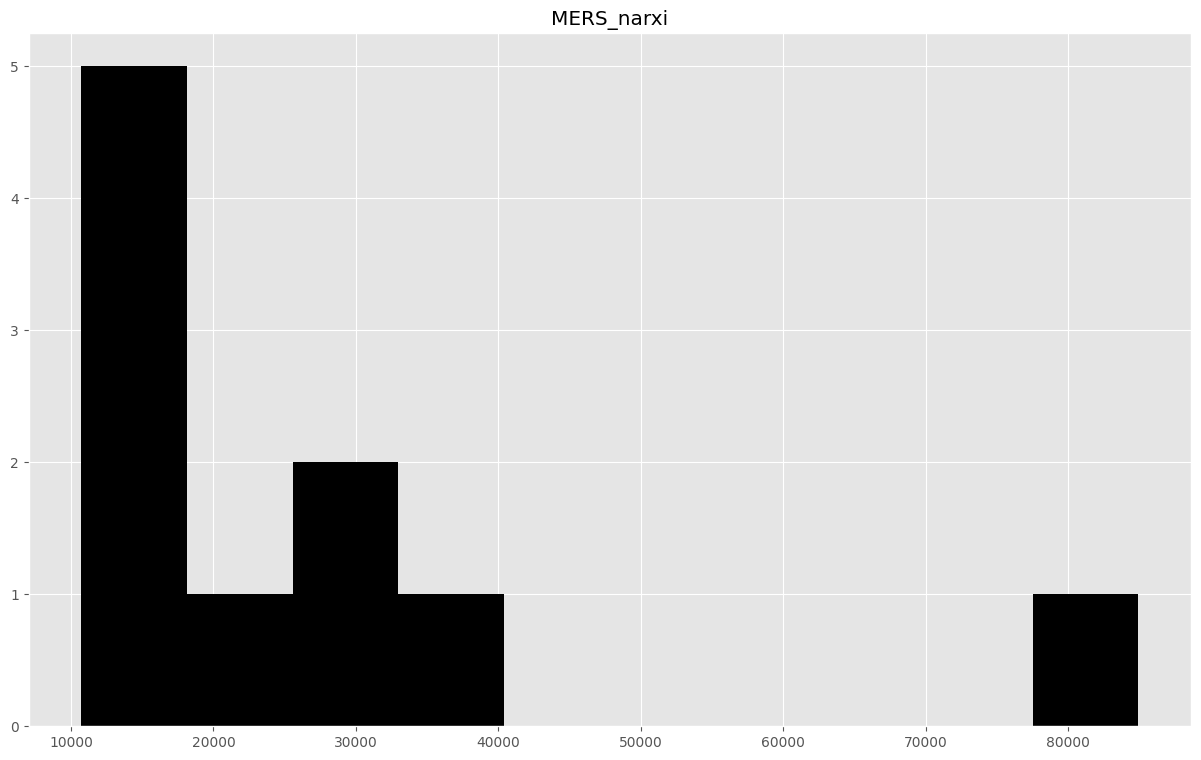

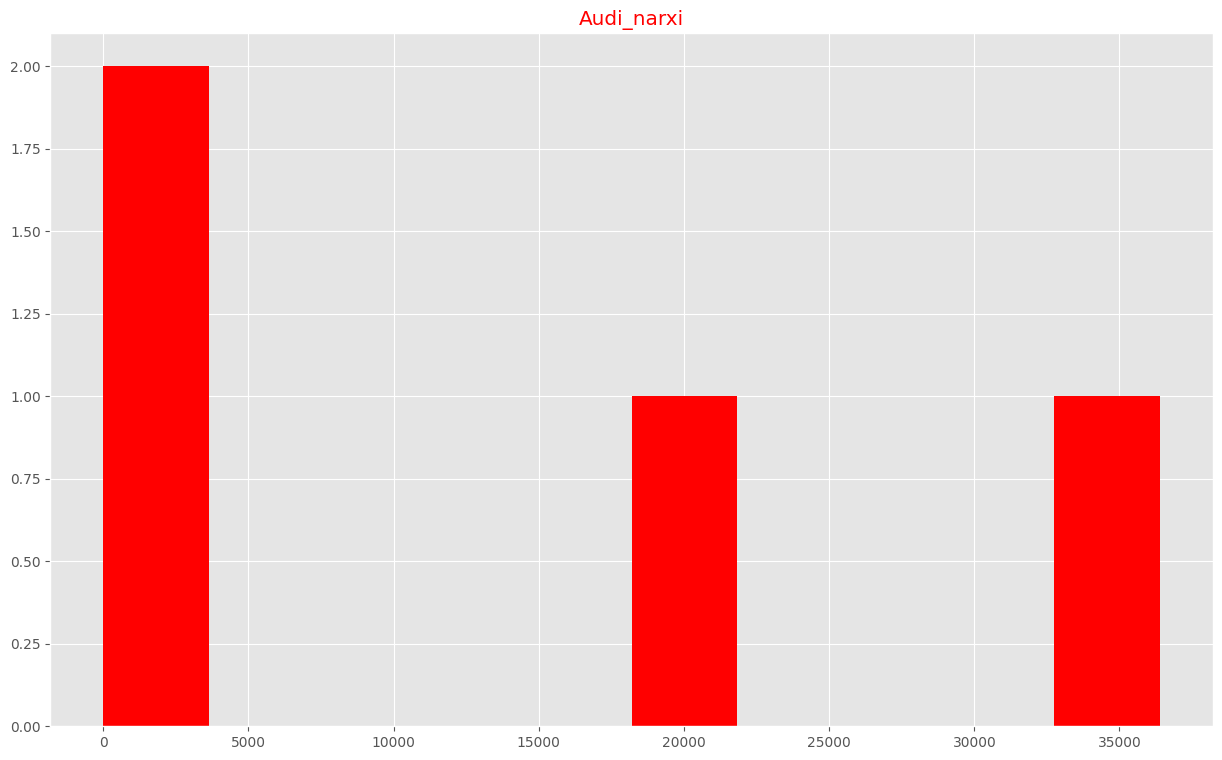

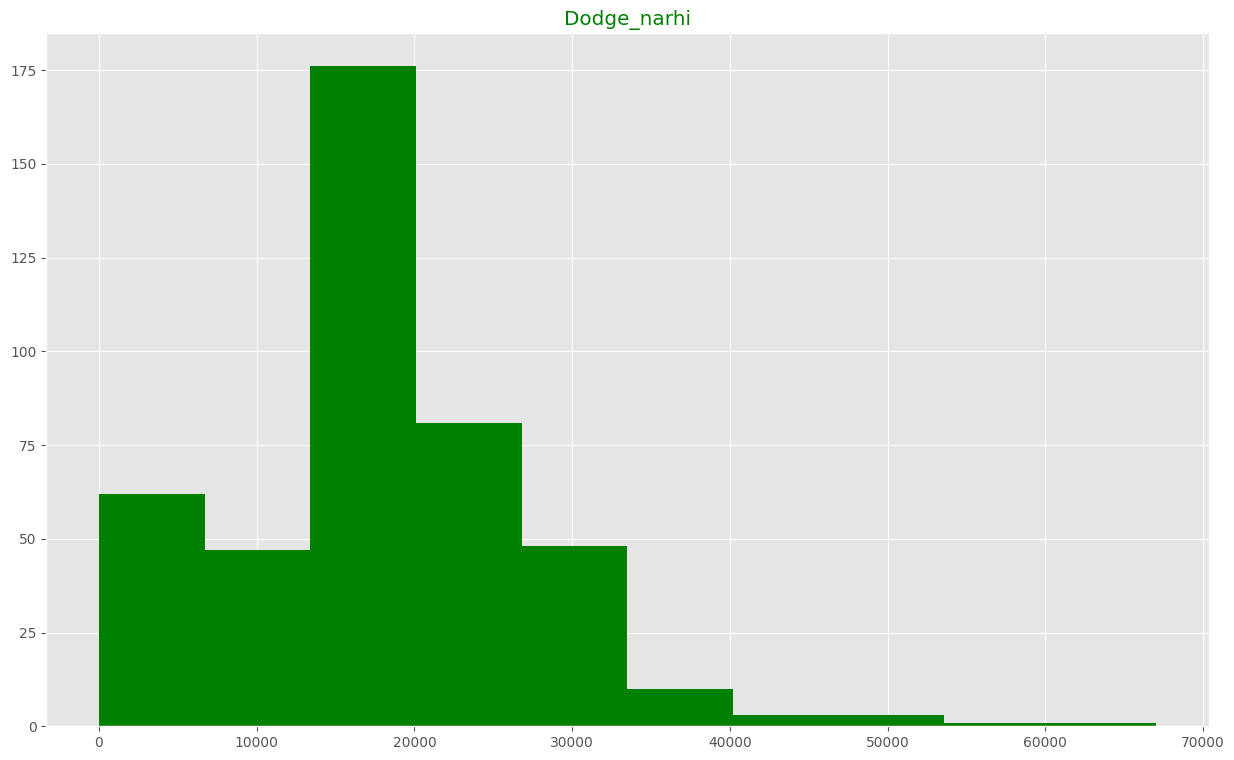

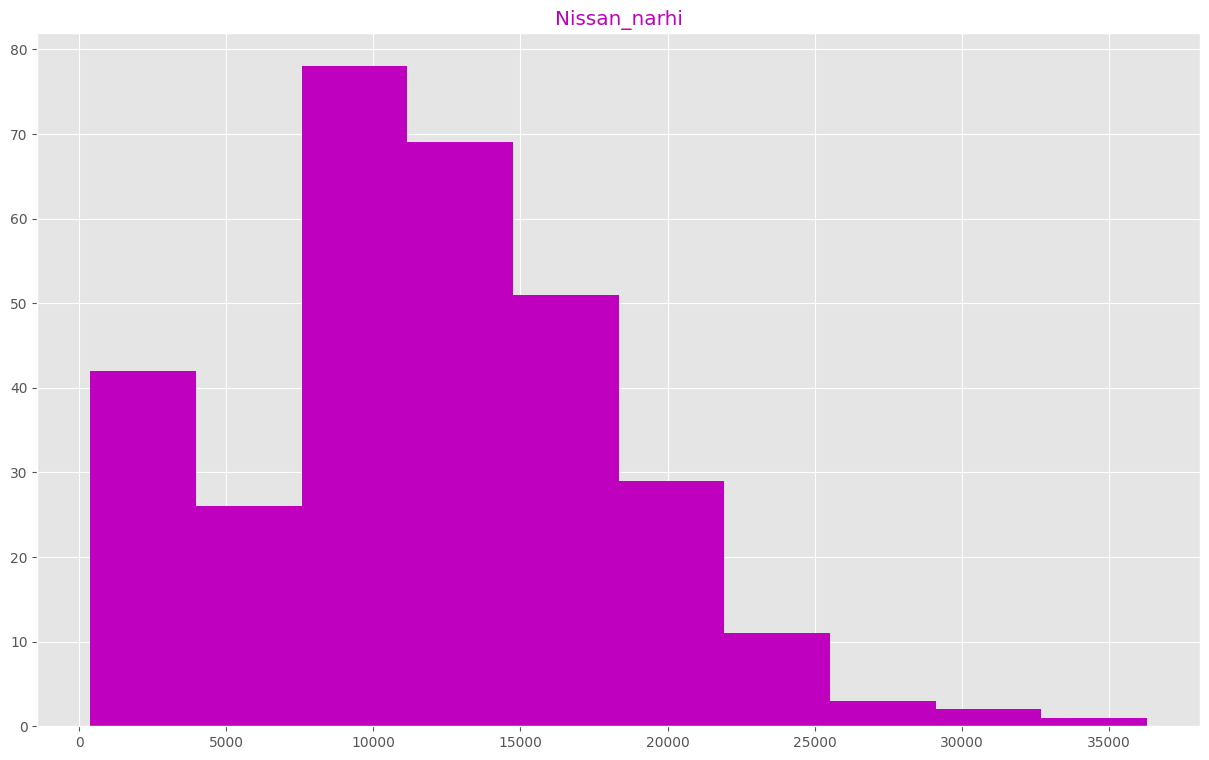

In [ ]:
sty.use('ggplot')
plt.figure(figsize=(15,9))
plt.title('BMW_narxi',color='lime')
plt.hist(df[df.brand=='bmw'].price, color = 'lime')
plt.show()

sty.use('ggplot')
plt.figure(figsize=(15,9))
plt.title('MERS_narxi',color='k')
plt.hist(df[df.brand=='mercedes-benz'].price, color = 'k')
plt.show()

sty.use('ggplot')
plt.figure(figsize=(15,9))
plt.title('Audi_narxi',color='red')
plt.hist(df[df.brand=='audi'].price, color = 'red')
plt.show()

sty.use('ggplot')
plt.figure(figsize=(15,9))
plt.title('Dodge_narhi',color='g')
plt.hist(df[df.brand=='dodge'].price, color = 'g')
plt.show()

sty.use('ggplot')
plt.figure(figsize=(15,9))
plt.title('Nissan_narhi',color='m')
plt.hist(df[df.brand=='nissan'].price, color = 'm')
plt.show()

<ipython-input-11-85535dc1c5fb>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,y=df['brand'],palette = "Set2")


<Axes: title={'center': 'The Rating'}, xlabel='count', ylabel='brand'>

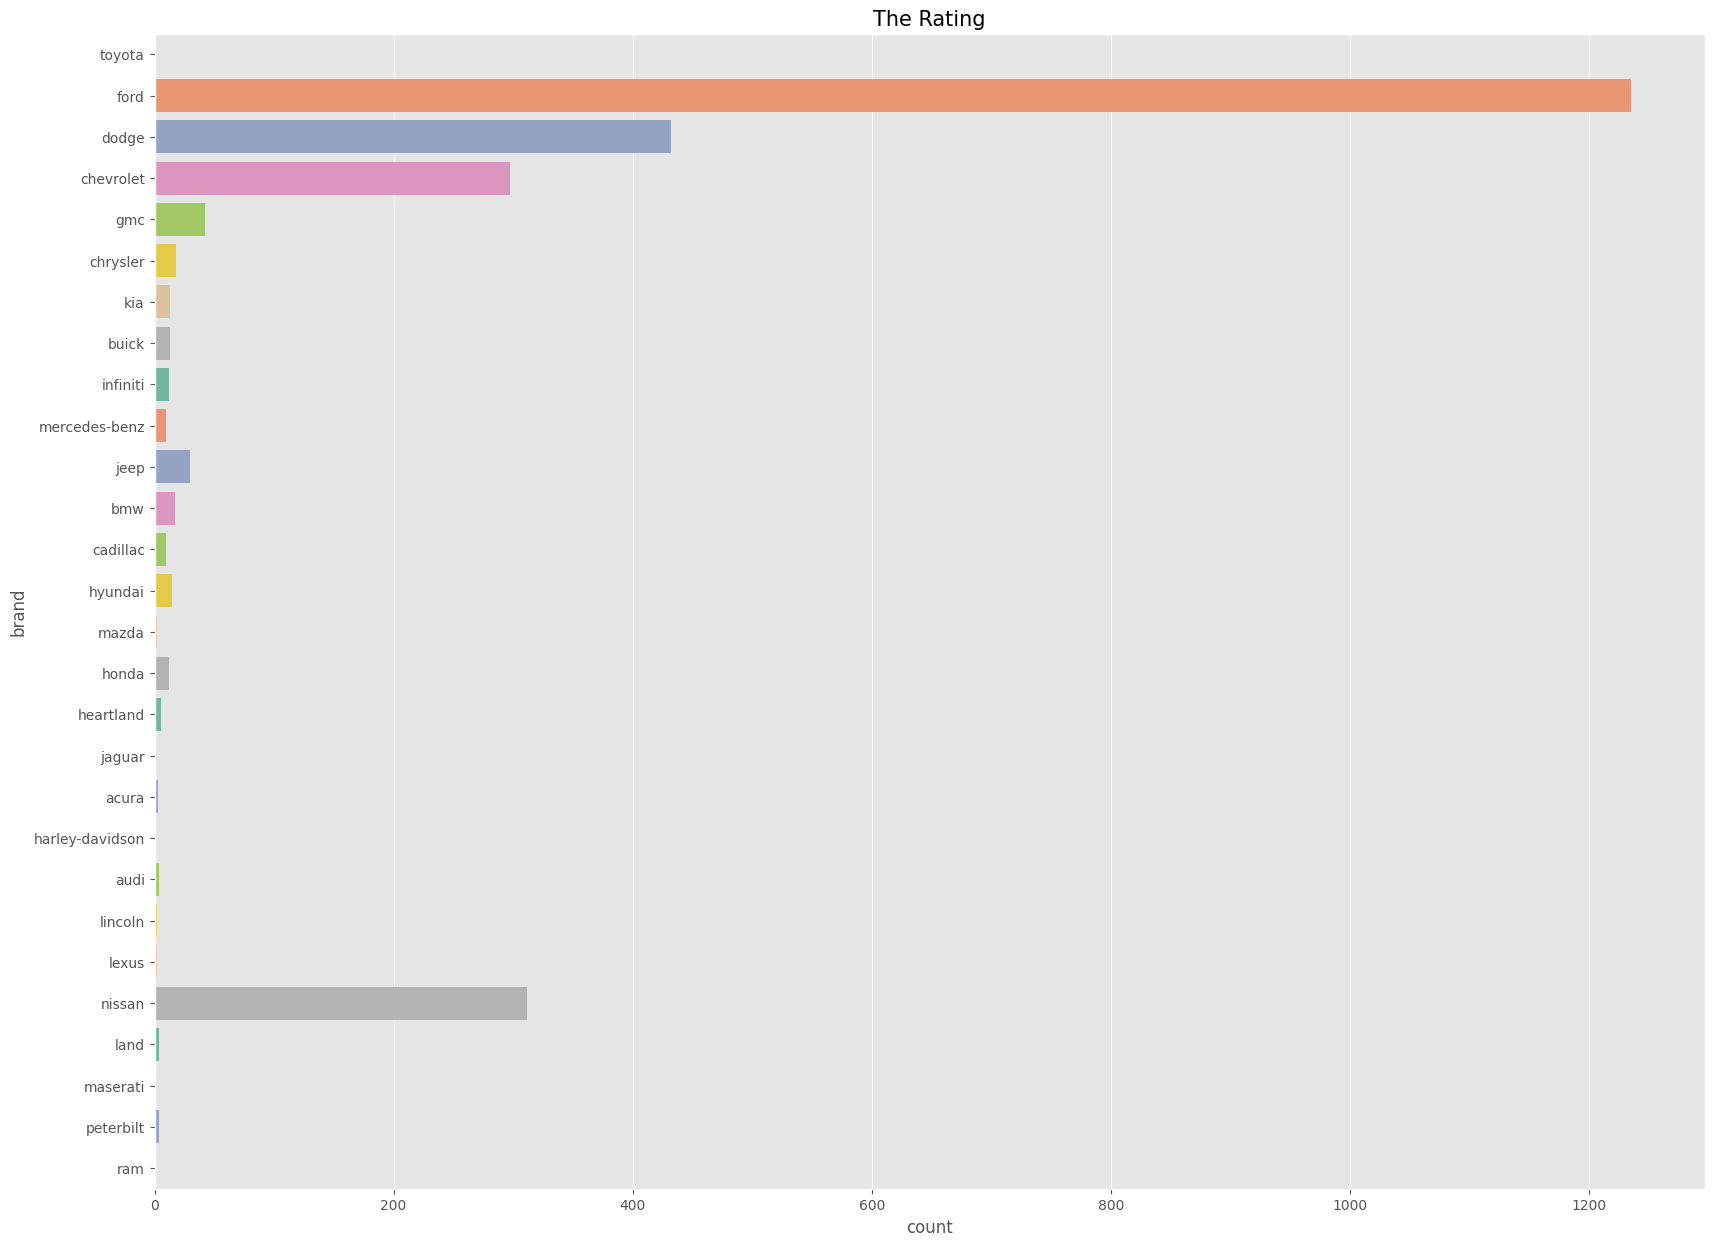

In [ ]:

plt.figure(figsize=(20, 15))
plt.title('The Rating', fontsize = 15)
sns.countplot(data=df,y=df['brand'],palette = "Set2")

<ipython-input-17-33d1ba7ea9e0>:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corrMatrix = df.corr()


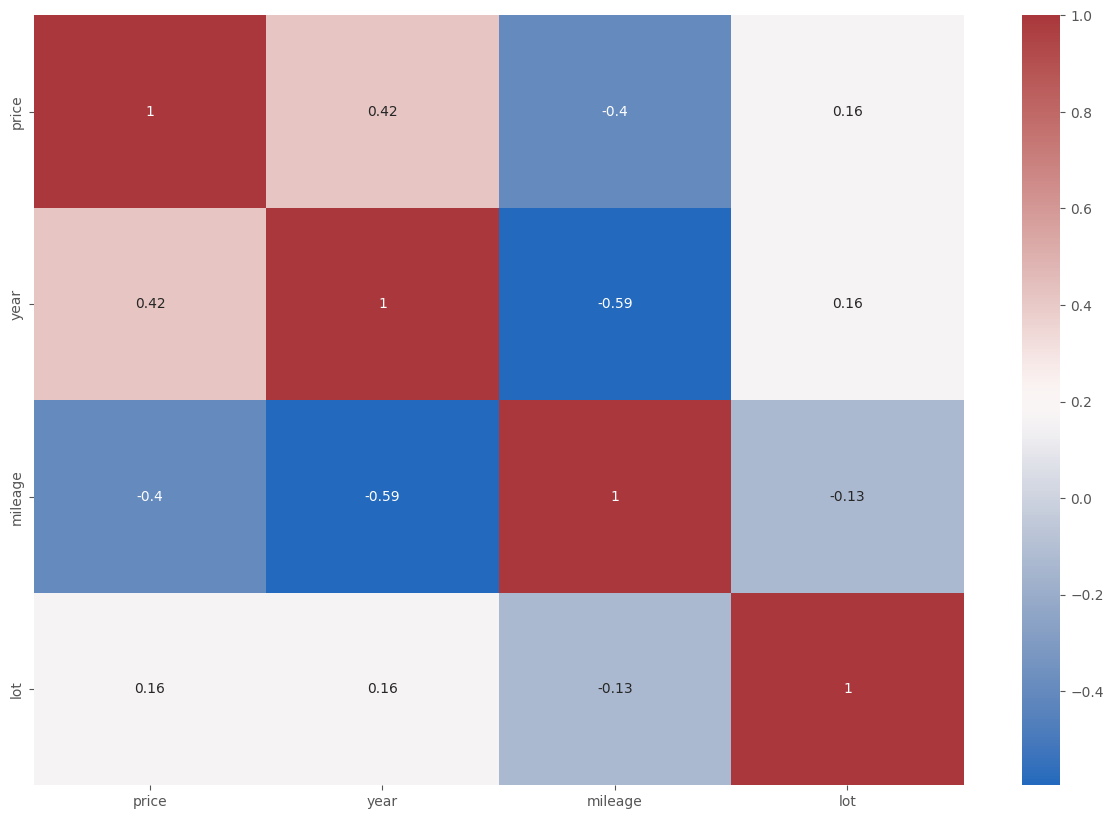

In [ ]:
corrMatrix = df.corr()
plt.figure(figsize=(15,10))
sns.heatmap(corrMatrix, annot=True, cmap='vlag')
plt.show()

In [ ]:
df.columns

Index(['price', 'brand', 'model', 'year', 'title_status', 'mileage', 'color',
       'vin', 'lot', 'state', 'country', 'condition'],
      dtype='object')

In [ ]:
df = df.drop(['brand', 'model', 'title_status', 'color', 'vin', 'state', 'country', 'condition'] ,axis=1)

In [ ]:
from sklearn.model_selection import train_test_split as trt
from sklearn.ensemble import RandomForestRegressor

In [ ]:
model = RandomForestRegressor()

x = df.drop(columns='price')
y = df['price']

In [ ]:
x_train, x_test, y_train, y_test = trt(x,y, test_size=0.2)

model.fit(x_train,y_train)

RandomForestRegressor()

In [ ]:
model.score(x_test, y_test)*100

48.811817246054645

In [ ]:
import joblib as jb

In [ ]:
jb.dump(model, 'Main')
main = jb.load('Main')

In [ ]:
main

RandomForestRegressor()